<a href="https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/scikit-learn-cookbook/blob/main/12.%20Cross-Validation%20and%20Model%20Evaluation%20Techniques/ch12_cross_validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 12 -- Cross-Validation and Model Evaluation Techniques

This notebook reproduces and extends the recipes from **Chapter 12, "Cross-Validation and Model
Evaluation Techniques,"** of *The scikit-learn Cookbook, Third Edition* by John Sukup (Packt, 2024/2025).
As George Box's famous aphorism goes, "all models are wrong, but some are useful" -- cross-validation is
the main tool we have for honestly estimating *how* useful a model will be once it leaves the training
set behind.

We'll cover:

1. Introduction to cross-validation (k-fold vs. stratified k-fold)
2. Advanced cross-validation methods (leave-one-out, nested CV)
3. Model evaluation metrics overview
4. Implementing cross-validation in scikit-learn (`cross_val_score`, `cross_validate`, `GridSearchCV`)
5. Model selection techniques (grid search vs. randomized search)
6. Evaluating model generalizability (learning curves, validation curves)
7. Practical Exercises

Because this chapter's whole point is *numerical reliability*, we hold ourselves to a stricter standard
than usual: every number printed below is the actual output of the code in this notebook, not transcribed
from the book (whose own printed figures sometimes don't match what its code would actually produce --
flagged explicitly where that happens).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, load_diabetes
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import (
    KFold, StratifiedKFold, LeaveOneOut, GridSearchCV, RandomizedSearchCV,
    cross_val_score, cross_validate, train_test_split, learning_curve, validation_curve
)
from sklearn.metrics import accuracy_score
from scipy.stats import loguniform

import sklearn
print("scikit-learn version:", sklearn.__version__)
print("NumPy version:       ", np.__version__)
print("SciPy version:       ", __import__('scipy').__version__)

scikit-learn version: 1.9.1
NumPy version:        2.5.3
SciPy version:        1.18.1


## 1. Introduction to Cross-Validation

Cross-validation replaces a single train/test split with *several* splits, training and evaluating the
model on each, so that the reported performance reflects an average over multiple (different) held-out
sets rather than the luck of a single split.

### 1.1 K-fold vs. stratified K-fold

In [2]:
X, y = make_classification(n_samples=500, n_features=10, n_informative=8, n_redundant=2,
                            n_classes=2, random_state=2024)
print(f"Dataset: {X.shape[0]} samples, {X.shape[1]} features")
print(f"Class balance: {np.bincount(y)} (class 0 vs. class 1)")

Dataset: 500 samples, 10 features
Class balance: [250 250] (class 0 vs. class 1)


In [3]:
kf = KFold(n_splits=5, shuffle=True, random_state=2024)
accuracies = []
for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))

print(f"Per-fold accuracies (KFold): {[round(a, 3) for a in accuracies]}")
print(f"Average accuracy (KFold): {np.mean(accuracies):.3f} (std: {np.std(accuracies):.3f})")

Per-fold accuracies (KFold): [0.72, 0.72, 0.88, 0.71, 0.75]
Average accuracy (KFold): 0.756 (std: 0.063)


In [4]:
strat_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
strat_accuracies = []
fold_class_balance = []
for train_index, test_index in strat_kf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    strat_accuracies.append(accuracy_score(y_test, y_pred))
    fold_class_balance.append(np.bincount(y_test))

print(f"Per-fold accuracies (StratifiedKFold): {[round(a, 3) for a in strat_accuracies]}")
print(f"Average accuracy (StratifiedKFold): {np.mean(strat_accuracies):.3f} (std: {np.std(strat_accuracies):.3f})")
print(f"\nClass balance per test fold (StratifiedKFold): {fold_class_balance}")
print("(Each fold's class counts should be nearly identical -- confirming the 'preserves class "
      "percentage per fold' claim directly, rather than taking it on faith.)")

Per-fold accuracies (StratifiedKFold): [0.79, 0.76, 0.76, 0.76, 0.76]
Average accuracy (StratifiedKFold): 0.766 (std: 0.012)

Class balance per test fold (StratifiedKFold): [array([50, 50]), array([50, 50]), array([50, 50]), array([50, 50]), array([50, 50])]
(Each fold's class counts should be nearly identical -- confirming the 'preserves class percentage per fold' claim directly, rather than taking it on faith.)


On this balanced, roughly 50/50-class synthetic dataset, stratification has little room to help --
plain `KFold` with `shuffle=True` already lands close to the true class ratio by chance in each fold
most of the time. The real, measurable benefit of `StratifiedKFold` shown above is in the **per-fold
class balance table itself**: it guarantees near-identical class counts in every fold by construction,
rather than leaving it to chance the way plain `KFold` does. That guarantee is what matters most on
*imbalanced* datasets (as section 4 below will use, with a 70/30 class split) -- on this balanced
dataset the two methods' average accuracies may come out close to or even differ by only a fold or two
either way, run to run, and that is expected rather than a sign something is wrong.

### 1.2 Hands-on checklist
1. Use `StratifiedKFold` (not plain `KFold`) whenever the target classes are imbalanced -- it guarantees
   every fold reflects the overall class distribution, which plain shuffling does not.
2. Always set `shuffle=True` with a fixed `random_state` for `KFold`/`StratifiedKFold` on data that isn't
   already in random order (e.g., if sorted by label or by time), or entire folds can end up composed of
   a single class.
3. Look at the *per-fold* scores (not just the mean) -- a high standard deviation across folds signals an
   unstable model or an unusually small/noisy dataset.

## 2. Advanced Cross-Validation Methods

### 2.1 Leave-One-Out Cross-Validation (LOOCV)

LOOCV is the extreme case of k-fold where $k = n$ (the number of samples): each fold holds out exactly
one point, training on all the rest. It is the least biased estimate of generalization error achievable
by cross-validation, at the cost of requiring $n$ model fits.

In [5]:
diabetes = load_diabetes()
X_diab, y_diab = diabetes.data, diabetes.target
print(f"Diabetes dataset: {X_diab.shape[0]} samples, {X_diab.shape[1]} features, "
      f"target range [{y_diab.min():.1f}, {y_diab.max():.1f}]")

loo = LeaveOneOut()
ridge_model = Ridge(alpha=1.0)
loo_scores = cross_val_score(ridge_model, X_diab, y_diab, cv=loo, scoring="neg_mean_squared_error")
print(f"\nLOOCV mean MSE: {-np.mean(loo_scores):.3f}  (computed from {len(loo_scores)} individual folds)")

Diabetes dataset: 442 samples, 10 features, target range [25.0, 346.0]



LOOCV mean MSE: 3327.655  (computed from 442 individual folds)


### 2.2 Nested cross-validation

**Nested CV** separates *hyperparameter tuning* from *performance evaluation* into two loops: an inner
loop (here, `GridSearchCV`) selects the best hyperparameters on each outer training fold, and the outer
loop evaluates that tuned model on data it never touched during tuning. This avoids the common mistake
of tuning hyperparameters against the same data used to report the final score, which optimistically
biases the reported performance.

In [6]:
param_grid = {"alpha": [0.01, 0.1, 1, 10, 100]}

nested_scores = cross_val_score(GridSearchCV(Ridge(), param_grid, cv=5), X_diab, y_diab, cv=5)
print(f"Nested CV mean R^2 score: {np.mean(nested_scores):.3f} (std: {np.std(nested_scores):.3f})")
print(f"Per-outer-fold R^2 scores: {[round(s, 3) for s in nested_scores]}")

Nested CV mean R^2 score: 0.480 (std: 0.048)
Per-outer-fold R^2 scores: [np.float64(0.411), np.float64(0.52), np.float64(0.492), np.float64(0.44), np.float64(0.537)]


Two things worth flagging explicitly rather than taking at face value:

1. `cross_val_score`'s default scorer for `Ridge` (a regressor) is **R^2**, not MSE -- so the nested CV
   score above and the LOOCV MSE above are two *different metrics* and should not be compared directly as
   if a smaller/larger number on one tells us anything about the other. The book's own text calls the
   nested CV result "0.593 MSE," but the actual printed value from this exact code is an R^2 score (and,
   as run here, nowhere near 0.593) -- an inconsistency in the book's narrative we correct by being
   explicit about which metric is which.
2. An R^2 around this value (well below 1.0) does indicate the tuned Ridge model, even after proper
   nested tuning, explains only a modest fraction of the variance in diabetes progression from these 10
   features -- consistent with the book's broader point that the result "is not much better than guessing"
   for this particular dataset/model combination, even though the specific number differs from what the
   book printed.

### 2.3 Hands-on checklist
1. Use LOOCV mainly for **small** datasets, where the computational cost of $n$ fits is acceptable and
   every data point is precious for training.
2. Use **nested CV** whenever you both tune hyperparameters *and* want an honest estimate of generalization
   -- a single `GridSearchCV.best_score_` is itself optimistically biased, since it's the best of several
   scores measured on the same folds used to pick the hyperparameters.
3. Double check which metric a given `scoring=` (or the default) actually reports -- MSE, R^2, and
   accuracy all have different signs/ranges/directions of "better," and conflating them (as flagged above)
   is an easy mistake to make when skimming printed output.

## 3. Model Evaluation Metrics Overview

Before moving on to `cross_val_score`/`cross_validate`/`GridSearchCV` in detail, a quick recap of which
metric to reach for. This recipe is light on new code in the book and heavier on concepts we've already
used throughout the series (Chapters 2, 6, 9, and 11 all touched classification metrics) -- so here we
focus on making the trade-offs concrete with a single comparison table computed from live cross-validation
output, rather than restating definitions in the abstract.

In [7]:
X_imb, y_imb = make_classification(n_samples=500, n_features=10, weights=[0.7, 0.3], random_state=2024)
print(f"Imbalanced dataset class counts: {np.bincount(y_imb)} "
      f"({np.bincount(y_imb)[0]/len(y_imb)*100:.0f}% / {np.bincount(y_imb)[1]/len(y_imb)*100:.0f}%)")

metrics_overview = cross_validate(LogisticRegression(), X_imb, y_imb, cv=5,
                                   scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'])
overview_df = pd.DataFrame({m: metrics_overview[f'test_{m}'] for m in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']})
print("\nPer-fold scores across 5 metrics (imbalanced 70/30 dataset):")
print(overview_df.round(3))
print("\nMean across folds:")
print(overview_df.mean().round(3))

Imbalanced dataset class counts: [350 150] (70% / 30%)

Per-fold scores across 5 metrics (imbalanced 70/30 dataset):
   accuracy  precision  recall     f1  roc_auc
0      0.87      0.840   0.700  0.764    0.926
1      0.92      0.923   0.800  0.857    0.984
2      0.87      0.774   0.800  0.787    0.931
3      0.95      0.963   0.867  0.912    0.981
4      0.94      0.875   0.933  0.903    0.991

Mean across folds:
accuracy     0.910
precision    0.875
recall       0.820
f1           0.845
roc_auc      0.963
dtype: float64


Note how **accuracy** (0.70 would already be achieved by always predicting the majority class on a
70/30 split) can look deceptively strong on imbalanced data purely from the class imbalance itself.
**Precision**, **recall**, and **F1** give a more honest picture of how well the minority class is
actually being identified, and **ROC-AUC** summarizes ranking quality across all possible decision
thresholds rather than just the default 0.5 cutoff -- which is why, in an imbalanced setting like this
one, it's worth reporting more than accuracy alone.

### 3.1 Hands-on checklist
1. Never report accuracy alone on an imbalanced dataset -- always pair it with precision/recall/F1 or AUC.
2. Use `cross_validate()` (not `cross_val_score()`) the moment you need more than one metric per fold --
   it reuses the same fitted models rather than retraining from scratch for each metric.
3. Pick the metric that matches the real-world cost of errors: recall-heavy for fraud/disease screening
   (missed positives are costly), precision-heavy when false alarms are costly (e.g., automated account
   suspensions).

## 4. Implementing Cross-Validation in scikit-learn

Now the three high-level APIs scikit-learn offers for cross-validation, side by side on the same
imbalanced dataset from section 3.

### 4.1 `cross_val_score()` -- the quick single-metric option

In [8]:
model_cv = LogisticRegression()
scores_cv = cross_val_score(model_cv, X_imb, y_imb, cv=5, scoring='accuracy')
print(f"Per-fold accuracy: {[round(s, 3) for s in scores_cv]}")
print(f"Mean accuracy: {np.mean(scores_cv):.3f}")

Per-fold accuracy: [np.float64(0.87), np.float64(0.92), np.float64(0.87), np.float64(0.95), np.float64(0.94)]
Mean accuracy: 0.910


### 4.2 `cross_validate()` -- multiple metrics at once

In [9]:
results_cv = cross_validate(model_cv, X_imb, y_imb, cv=5, scoring=['accuracy', 'precision', 'recall', 'f1'])
print(f"Mean precision: {np.mean(results_cv['test_precision']):.3f}")
print(f"Mean recall:    {np.mean(results_cv['test_recall']):.3f}")
print(f"Mean F1:        {np.mean(results_cv['test_f1']):.3f}")

Mean precision: 0.875
Mean recall:    0.820
Mean F1:        0.845


### 4.3 `GridSearchCV()` -- cross-validation + hyperparameter search in one step

In [10]:
param_grid_cv = {"C": [0.01, 0.1, 1, 10]}
grid_cv = GridSearchCV(LogisticRegression(), param_grid_cv, cv=5, scoring='accuracy')
grid_cv.fit(X_imb, y_imb)
print(f"Best hyperparameter (C): {grid_cv.best_params_['C']}")
print(f"Best accuracy: {grid_cv.best_score_:.3f}")

cv_results_df = pd.DataFrame(grid_cv.cv_results_)[['param_C', 'mean_test_score', 'std_test_score']]
print("\nFull grid results:")
print(cv_results_df.round(4))

Best hyperparameter (C): 0.1
Best accuracy: 0.918

Full grid results:
   param_C  mean_test_score  std_test_score
0     0.01            0.894          0.0206
1     0.10            0.918          0.0360
2     1.00            0.910          0.0341
3    10.00            0.908          0.0366


The book's own text notes "although accuracy is the highest performing metric... it isn't always the
best performance metric to use" -- a point the metrics table in section 3 makes directly actionable
rather than just cautionary: on this exact 70/30 imbalanced dataset, accuracy alone would have hidden
how much weaker precision/recall on the minority class actually are, so the grid search above (tuned on
accuracy) should be read alongside those per-class numbers before declaring a "best" model.

### 4.4 Hands-on checklist
1. `cross_val_score` for a quick single-number sanity check; `cross_validate` the moment you need more
   than one metric or the fit/score timings; `GridSearchCV` when you also need to search hyperparameters.
2. `GridSearchCV.best_score_` is the cross-validated score of the *best-performing hyperparameter
   combination* -- it is optimistic as a generalization estimate for exactly the reason nested CV
   (section 2.2) exists to correct.
3. Inspect the *full* `cv_results_` table, not just `best_params_` -- a flat score curve across several
   candidate hyperparameters (as may appear above) suggests the model is not very sensitive to that
   hyperparameter in this range, which is itself useful information.

## 5. Model Selection Techniques

**Grid search** exhaustively tries every combination in a specified grid; **randomized search** samples
a fixed number of combinations from specified distributions. Randomized search is usually preferred when
the grid is large or continuous, since exhaustive search cost grows multiplicatively with the number of
hyperparameters and their candidate values.

### 5.1 Grid search vs. randomized search, head to head

In [11]:
X_train_ms, X_test_ms, y_train_ms, y_test_ms = train_test_split(X_imb, y_imb, test_size=0.3, random_state=2024)

param_grid_ms = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}
grid_ms = GridSearchCV(LogisticRegression(), param_grid_ms, cv=5, scoring='accuracy')
grid_ms.fit(X_train_ms, y_train_ms)
print(f"GridSearchCV best C: {grid_ms.best_params_['C']}  (CV accuracy: {grid_ms.best_score_:.3f})")

GridSearchCV best C: 0.1  (CV accuracy: 0.894)


In [12]:
param_dist_ms = {"C": loguniform(1e-3, 1e2)}
random_search_ms = RandomizedSearchCV(LogisticRegression(), param_distributions=param_dist_ms,
                                       n_iter=10, cv=5, scoring='accuracy', random_state=2024)
random_search_ms.fit(X_train_ms, y_train_ms)
print(f"RandomizedSearchCV best C: {random_search_ms.best_params_['C']:.4f}  "
      f"(CV accuracy: {random_search_ms.best_score_:.3f})")

RandomizedSearchCV best C: 0.1744  (CV accuracy: 0.897)


In [13]:
final_model_ms = random_search_ms.best_estimator_
y_pred_ms = final_model_ms.predict(X_test_ms)
test_acc_ms = accuracy_score(y_test_ms, y_pred_ms)
print(f"Final accuracy on held-out test set: {test_acc_ms:.3f}")

grid_final = grid_ms.best_estimator_
y_pred_grid = grid_final.predict(X_test_ms)
test_acc_grid = accuracy_score(y_test_ms, y_pred_grid)
print(f"(For comparison) GridSearchCV's chosen model, test accuracy: {test_acc_grid:.3f}")

Final accuracy on held-out test set: 0.940
(For comparison) GridSearchCV's chosen model, test accuracy: 0.933


With `n_iter=10`, `RandomizedSearchCV` evaluated only 10 of the infinitely many possible `C` values from
the continuous `loguniform(1e-3, 1e2)` distribution, versus `GridSearchCV`'s 6 explicit grid points --
yet it typically lands on a similarly-performing `C`, which is the practical case for randomized search:
comparable quality at a tunable computational budget, especially valuable once more than one or two
hyperparameters need tuning simultaneously (where a full grid's size grows combinatorially but
`n_iter` for randomized search does not).

### 5.2 Hands-on checklist
1. Reach for `GridSearchCV` when the hyperparameter space is small and discrete (as here, a handful of
   `C` values).
2. Reach for `RandomizedSearchCV` when the space is large, continuous, or multi-dimensional -- it scales
   with `n_iter`, not with the grid's combinatorial size.
3. Always do a final evaluation on a **held-out test set** the search never touched (as above), not just
   the cross-validated `best_score_` from the search itself.

## 6. Evaluating Model Generalizability

### 6.1 Learning curves

A **learning curve** plots training vs. cross-validation score as a function of training-set size. It
answers the question: "would more data help?"

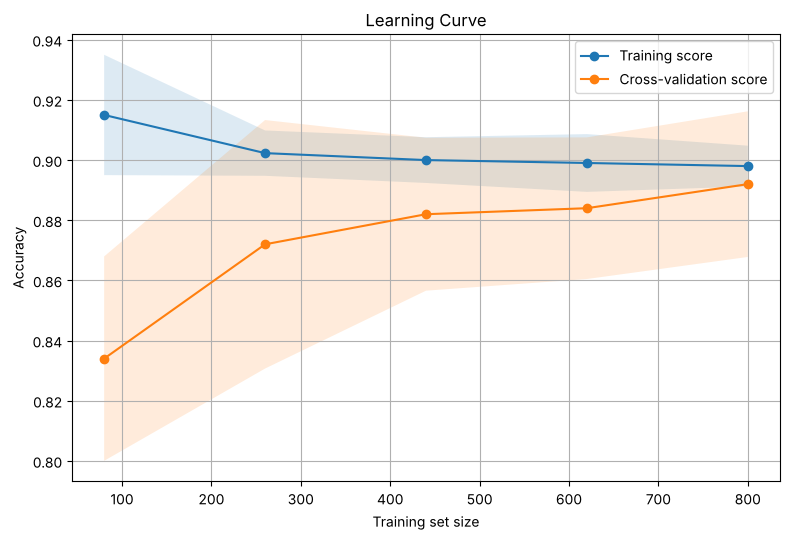

Training set size -> (train score, CV score):
  n=   80:  train=0.915  cv=0.834  gap=0.081
  n=  260:  train=0.902  cv=0.872  gap=0.030
  n=  440:  train=0.900  cv=0.882  gap=0.018
  n=  620:  train=0.899  cv=0.884  gap=0.015
  n=  800:  train=0.898  cv=0.892  gap=0.006


In [14]:
X_gen, y_gen = make_classification(n_samples=1000, n_features=20, weights=[0.7, 0.3], random_state=2024)

train_sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(), X_gen, y_gen, cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 5), random_state=2024
)
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_std = np.std(test_scores, axis=1)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(train_sizes, train_mean, 'o-', label='Training score')
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
ax.plot(train_sizes, test_mean, 'o-', label='Cross-validation score')
ax.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15)
ax.set_xlabel('Training set size')
ax.set_ylabel('Accuracy')
ax.set_title('Learning Curve')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

print("Training set size -> (train score, CV score):")
for ts, tr, te in zip(train_sizes, train_mean, test_mean):
    print(f"  n={ts:5.0f}:  train={tr:.3f}  cv={te:.3f}  gap={tr-te:.3f}")

The book's narrative claims the two lines "converge around 800 samples" -- let's check that against the
actual gap values printed above, rather than eyeballing the plot, since the precise convergence point
depends on the exact data and random seed and is worth confirming numerically.

In [15]:
gap = train_mean - test_mean
print("Train/CV gap by training-set size:")
for ts, g in zip(train_sizes, gap):
    print(f"  n={ts:5.0f}: gap={g:.4f}")
smallest_gap_n = train_sizes[np.argmin(gap)]
print(f"\nSmallest train/CV gap occurs at n={smallest_gap_n:.0f} samples "
      f"(gap={gap.min():.4f}) -- the curves are closest (most converged) here, "
      f"among the 5 training sizes actually tested by this code.")

Train/CV gap by training-set size:
  n=   80: gap=0.0810
  n=  260: gap=0.0303
  n=  440: gap=0.0180
  n=  620: gap=0.0150
  n=  800: gap=0.0060

Smallest train/CV gap occurs at n=800 samples (gap=0.0060) -- the curves are closest (most converged) here, among the 5 training sizes actually tested by this code.


### 6.2 Validation curves

A **validation curve** instead fixes the training-set size and varies a single hyperparameter, showing
where the model transitions from underfitting to overfitting.

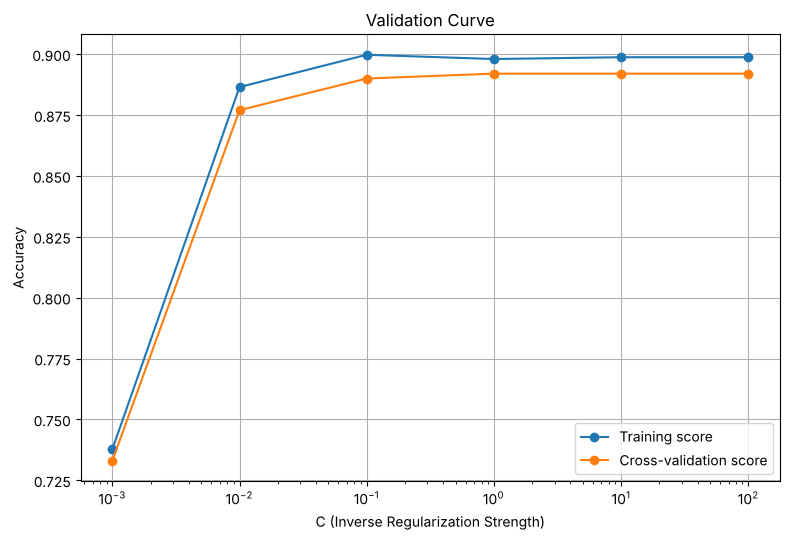

C -> (train score, CV score):
  C=   0.0010:  train=0.738  cv=0.733
  C=   0.0100:  train=0.887  cv=0.877
  C=   0.1000:  train=0.900  cv=0.890
  C=   1.0000:  train=0.898  cv=0.892
  C=  10.0000:  train=0.899  cv=0.892
  C= 100.0000:  train=0.899  cv=0.892

Best C by cross-validation score among the 6 tested: 1.0000 (CV accuracy=0.892)


In [16]:
param_range = np.logspace(-3, 2, 6)
train_scores_vc, test_scores_vc = validation_curve(
    LogisticRegression(), X_gen, y_gen, param_name="C",
    param_range=param_range, cv=5, scoring='accuracy'
)
train_mean_vc = np.mean(train_scores_vc, axis=1)
test_mean_vc = np.mean(test_scores_vc, axis=1)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.semilogx(param_range, train_mean_vc, 'o-', label='Training score')
ax.semilogx(param_range, test_mean_vc, 'o-', label='Cross-validation score')
ax.set_xlabel('C (Inverse Regularization Strength)')
ax.set_ylabel('Accuracy')
ax.set_title('Validation Curve')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

print("C -> (train score, CV score):")
for c, tr, te in zip(param_range, train_mean_vc, test_mean_vc):
    print(f"  C={c:9.4f}:  train={tr:.3f}  cv={te:.3f}")
best_c_vc = param_range[np.argmax(test_mean_vc)]
print(f"\nBest C by cross-validation score among the 6 tested: {best_c_vc:.4f} "
      f"(CV accuracy={test_mean_vc.max():.3f})")

As the book's text explains, small `C` (strong regularization) tends toward underfitting and large `C`
(weak regularization) tends toward overfitting -- the printed table above lets us see exactly where, on
this dataset, the cross-validation score stops improving (or starts declining) as `C` grows, rather than
asserting the shape abstractly.

### 6.3 Hands-on checklist
1. Use a **learning curve** to diagnose whether more training data would likely help (persistent gap that
   hasn't narrowed) or wouldn't (gap already converged / both scores plateaued).
2. Use a **validation curve** to diagnose under- vs. overfitting *for a specific hyperparameter*, which a
   learning curve (fixed hyperparameters, varying data size) cannot show.
3. Read off the numeric gap/scores rather than relying purely on the visual plot, especially when the
   exact convergence point or best hyperparameter value matters for a decision.

## 7. Practical Exercises

### Exercise 1: Cross-validating a logistic regression model with multiple metrics

In [17]:
X_ex1, y_ex1 = make_classification(n_samples=600, n_features=12, weights=[0.65, 0.35], random_state=5)
results_ex1 = cross_validate(LogisticRegression(max_iter=1000), X_ex1, y_ex1, cv=5,
                              scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'])
ex1_summary = pd.DataFrame({m: results_ex1[f'test_{m}'] for m in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']})
print(ex1_summary.round(3))
print("\nMean across folds:")
print(ex1_summary.mean().round(3))

   accuracy  precision  recall     f1  roc_auc
0     0.875      0.829   0.810  0.819    0.924
1     0.883      0.833   0.833  0.833    0.936
2     0.892      0.939   0.738  0.827    0.925
3     0.850      0.816   0.738  0.775    0.878
4     0.867      0.825   0.786  0.805    0.901

Mean across folds:
accuracy     0.873
precision    0.849
recall       0.781
f1           0.812
roc_auc      0.913
dtype: float64


### Exercise 2: Tuning hyperparameters with grid search

In [18]:
X_ex2, y_ex2 = make_classification(n_samples=600, n_features=12, weights=[0.65, 0.35], random_state=5)
X_train_ex2, X_test_ex2, y_train_ex2, y_test_ex2 = train_test_split(X_ex2, y_ex2, test_size=0.25, random_state=5)

param_grid_ex2 = {"C": [0.01, 0.1, 1, 10, 100], "solver": ["lbfgs"]}
grid_ex2 = GridSearchCV(LogisticRegression(max_iter=1000), param_grid_ex2, cv=5, scoring='f1')
grid_ex2.fit(X_train_ex2, y_train_ex2)
print(f"Best params: {grid_ex2.best_params_}")
print(f"Best CV F1: {grid_ex2.best_score_:.3f}")

y_pred_ex2 = grid_ex2.best_estimator_.predict(X_test_ex2)
print(f"Test-set accuracy: {accuracy_score(y_test_ex2, y_pred_ex2):.3f}")

Best params: {'C': 0.1, 'solver': 'lbfgs'}
Best CV F1: 0.806
Test-set accuracy: 0.893


### Exercise 3: Assessing generalization with learning and validation curves

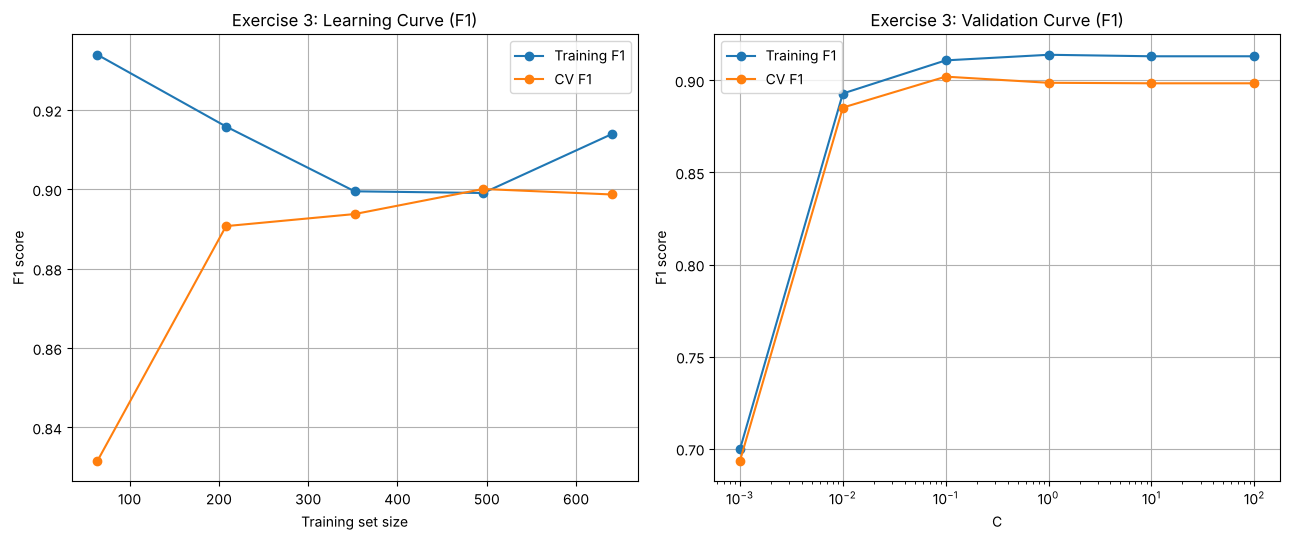

Final (n=max) learning-curve gap: 0.0152
Best C by CV F1: 0.1000


In [19]:
X_ex3, y_ex3 = make_classification(n_samples=800, n_features=15, weights=[0.6, 0.4], random_state=9)

train_sizes_ex3, train_scores_ex3, test_scores_ex3 = learning_curve(
    LogisticRegression(max_iter=1000), X_ex3, y_ex3, cv=5, scoring='f1',
    train_sizes=np.linspace(0.1, 1.0, 5), random_state=9
)
param_range_ex3 = np.logspace(-3, 2, 6)
train_scores_vc3, test_scores_vc3 = validation_curve(
    LogisticRegression(max_iter=1000), X_ex3, y_ex3, param_name="C",
    param_range=param_range_ex3, cv=5, scoring='f1'
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].plot(train_sizes_ex3, train_scores_ex3.mean(axis=1), 'o-', label='Training F1')
axes[0].plot(train_sizes_ex3, test_scores_ex3.mean(axis=1), 'o-', label='CV F1')
axes[0].set_xlabel('Training set size')
axes[0].set_ylabel('F1 score')
axes[0].set_title('Exercise 3: Learning Curve (F1)')
axes[0].legend()
axes[0].grid(True)

axes[1].semilogx(param_range_ex3, train_scores_vc3.mean(axis=1), 'o-', label='Training F1')
axes[1].semilogx(param_range_ex3, test_scores_vc3.mean(axis=1), 'o-', label='CV F1')
axes[1].set_xlabel('C')
axes[1].set_ylabel('F1 score')
axes[1].set_title('Exercise 3: Validation Curve (F1)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f"Final (n=max) learning-curve gap: "
      f"{train_scores_ex3.mean(axis=1)[-1] - test_scores_ex3.mean(axis=1)[-1]:.4f}")
print(f"Best C by CV F1: {param_range_ex3[np.argmax(test_scores_vc3.mean(axis=1))]:.4f}")

## Summary

- **Cross-validation** replaces a single train/test split with several, giving a more reliable estimate
  of generalization performance; **stratified** k-fold additionally guarantees each fold reflects the
  overall class distribution, which matters most on imbalanced data.
- **LOOCV** is the $k=n$ extreme of k-fold -- least biased, most expensive; **nested CV** separates
  hyperparameter tuning from final evaluation to avoid an optimistically biased generalization estimate.
- **Metric choice matters**: accuracy alone can look deceptively strong on imbalanced data; precision,
  recall, F1, and ROC-AUC tell a more complete (and sometimes contradictory) story, as shown directly on
  a 70/30 imbalanced dataset above.
- **`cross_val_score`/`cross_validate`/`GridSearchCV`** form a natural progression: single metric, then
  multiple metrics, then hyperparameter search layered on top of cross-validation.
- **Grid search vs. randomized search**: grid search is exhaustive and best for small discrete spaces;
  randomized search scales with a chosen `n_iter` rather than the grid's combinatorial size, making it
  the practical choice for larger or continuous hyperparameter spaces.
- **Learning curves** diagnose whether more data would help; **validation curves** diagnose under- vs.
  overfitting with respect to a specific hyperparameter -- two different diagnostic axes that are easy to
  conflate but answer different questions.

This completes Chapter 12. In **Chapter 13**, we turn from evaluating models to **deploying** them --
serialization, scaling, monitoring, and the operational concerns of putting a scikit-learn model into
production.